# KAHM soft-state forecasting: from representation to a checked risk bound

**Guided demonstration · version 0.1.0**

This notebook connects one observed history to its geometry-induced features,
three fitted forecasts, and the archived evidence supporting their fitted-risk
bounds. It uses the completed four-state benchmark supplied with this package.

You will learn to:

1. Identify exactly what has been inspected or recomputed.
2. Read RAW, KAHM MEM, and KAHM LOCAL representations for the same history.
3. Distinguish calibration error **q**, a statistical upper bound **U**, and the
   benchmark's exact population risk **R**.
4. Launch a separate fresh experiment and understand what must change for new data.

**Default: archive inspection.** Saved outputs below are an executed inspection
example. They do not certify the runtime in which you open this file. Run the
cells in order; change `MODE` to `"verify"` only when you intend full numerical
verification. The mode is repeated in each results section.


## 1. Choose a path

From the complete project directory, use Python 3.12 or newer:

```bash
python -m pip install '.[tutorial]'
python -m jupyterlab notebooks/01_kahm_certified_forecasting.ipynb
```

| Path | Work performed | Numerical runtime requirement |
| --- | --- | --- |
| `inspect` — default | Check fixed archive hashes and bindings; display recorded features, forecasts, q, U, and R | No original-runtime match required |
| `verify` — explicit | Inspect identities, verify the existing freeze and certificate, recompute exact benchmark risks, replay forecasts | Must match the archived Python build, NumPy build/BLAS configuration, and execution sources |
| Fresh experiment — separate command | Fit, select, freeze, calibrate, certify, and audit a new run | Creates new identities in the supported current runtime |

For a terminal-only introduction, use `python -m kahm_demo tutorial --project .`
or `python -m examples.guided_tutorial --project .`. The supplied HTML version
is a static reading copy with recorded inspection outputs. Neither inspection
nor this notebook's **Run All** starts a fresh experiment.


In [1]:
from pathlib import Path
from html import escape
import json
from IPython.display import HTML, Image, display
from kahm_demo.tutorial import (
    history_from_observations, inspect_primary, runtime_compatibility, verify_primary,
)

# Open from the project root or its notebooks directory. Otherwise set PROJECT explicitly.
PROJECT = next((p for p in (Path.cwd(), Path.cwd().parent)
                if (p / "frozen/primary/freeze.json").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Set PROJECT to the complete project directory.")
MODE = "inspect"  # The only alternative is "verify". No automatic fallback.
HISTORY = (0.25, 0.75)  # Previous observation, current observation.
history_labels = history_from_observations(HISTORY)

def show_table(title, columns, rows, *, mode):
    heading = "".join(f"<th>{escape(str(value))}</th>" for value in columns)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row)
                   + "</tr>" for row in rows)
    display(HTML(f"<div class='kahm-results'><p><strong>{escape(title)}</strong>"
                 f" · <code>{escape(mode)}</code></p>"
                 f"<div style='overflow-x:auto'><table><thead><tr>{heading}</tr></thead>"
                 f"<tbody>{body}</tbody></table></div></div>"))

print("Requested mode:", MODE)
print("Observed history:", HISTORY, "→ benchmark state labels:", history_labels)


Requested mode: inspect
Observed history: (0.25, 0.75) → benchmark state labels: (1, 2)


## 2. Establish the scope before reading a result

`inspect_primary` checks the three fixed release anchors and their bound payload
inventories. It reads the recorded results without evaluating a model, checking
a confidence-endpoint inequality, or recomputing a population expectation.
This is useful for learning and for checking that the archive is intact.

`verify_primary` invokes the strict existing verification chain and then replays
the three selected-history predictions. It does not refit models, sample new
calibration observations, or search for new endpoints.

Verification stops on an incompatible runtime or changed evidence. It never
substitutes archive inspection for a failed numerical check. Python and NumPy
version pins alone are insufficient: the stored identity also includes the full
Python build string and NumPy/BLAS build configuration. A mismatch calls for an
explicit fresh run in your environment, with its own freeze and assessment.


In [2]:
# Clear a previous result before attempting a new mode in this kernel.
result = None
if MODE == "inspect":
    result = inspect_primary(PROJECT, history=history_labels)
elif MODE == "verify":
    compatibility = runtime_compatibility(PROJECT)
    if not compatibility["compatible"]:
        print(json.dumps({key: compatibility[key] for key in
                          ("dependency_status", "runtime_differences", "source_differences",
                           "source_roster_differences")}, indent=2))
        raise RuntimeError("Verification did not run: runtime/source mismatch. See the fresh-run section.")
    result = verify_primary(PROJECT, history=history_labels)
else:
    raise ValueError("MODE must be 'inspect' or 'verify'.")

show_table("What this execution established", ("Check", "Completed"),
           [(key, result[key]) for key in ("archive_identity_checked", "model_replayed",
             "certificate_reverified", "population_risk_recomputed")], mode=result["mode"])
print(result["scope"])


Recorded values match the released primary anchors and payload bytes. No model, loss, endpoint, or population-risk computation has been rerun. Runtime/source compatibility is a separate precheck; strict numerical verification is explicit.


Check,Completed
archive_identity_checked,True
model_replayed,False
certificate_reverified,False
population_risk_recomputed,False


In [3]:
show_table("Primary evidence identities", ("Record", "SHA-256"),
           list(result["anchors"].items()), mode=result["mode"])


Record,SHA-256
freeze_sha256,d9de3f2511dd70a2f1a9eaf7fb7fbb772cfa192a4d141ff472d7e032efeed5e5
certificate_sha256,b7586d0afa78c0f832feb482132499bd923d5bf35cdd53bd5e84f52f6d9c9446
audit_sha256,65e1bd54dcbc87994f197b15d6fd0f7e56a0f8eb2ef1cb4b699022d2e02c52eb


## 3. One benchmark, three matched representations

The observation alphabet is **0, 0.25, 0.75, 1**, indexed by four state labels.
The history contains two observations in time order. There are 16 possible
histories and 64 history-target combinations. The package supplies independent
episodes under a stipulated stationary history and transition law; it does not
treat overlapping windows from a single trajectory as independent calibration.
Each episode draws an ordered state pair `(a, b)` uniformly. Its next state is
`(a + b) mod 4` with probability 17/20, and each other state with probability 1/20.

The public primary development run used 4,096 training episodes and 1,024 validation
episodes. It retained all 225 declared readout candidates, then froze the selected
RAW, MEM, and LOCAL predictors before accessing the 4,096 calibration outcomes.
MEM and LOCAL use the same validation-selected bank. The selected bank and
actual widths appear in the recorded result below.

| Representation | Input to the readout feature/scaling stage | Width |
| --- | --- | ---: |
| RAW | Two observations after stored training-only standardization | 2 |
| KAHM MEM | Concatenated soft memberships for two partitions | 6 |
| KAHM LOCAL | The same six memberships plus membership-weighted local PCA coordinates of the input | Determined by the selected bank |

Each partition's memberships normalize separately. The concatenation is not
one six-way probability distribution. These are geometry-induced features;
the demonstration does not identify them as latent-state posterior probabilities.
For standardized history `z`, each LOCAL block is `phi_j * P_j.T @ (z - mu_j)`:
membership times the input's centered local coordinates, not the reconstruction.


In [4]:
encoder = result["history"]["recorded_encoder"]
show_table("Recorded representation widths before decoder scaling", ("Representation", "Width"),
           [("RAW", len(encoder["raw"])), ("KAHM MEM", len(encoder["memberships"])),
            ("KAHM LOCAL", len(encoder["enriched"]))], mode=result["mode"])
print("Selected bank:", encoder["bank_id"])
print("Recorded RAW (training-standardized history):", encoder["raw"])
print("Recorded KAHM MEM:", encoder["memberships"])
print("Recorded KAHM LOCAL:", encoder["enriched"])
show_table("Separate membership normalizations", ("Partition", "Groups", "Memberships", "Displayed sum"),
           [(group["partition_id"], group["group_count"],
             ", ".join(f"{value:.6f}" for value in group["memberships"]),
             f"{sum(group['memberships']):.12f}") for group in encoder["partition_groups"]],
           mode=result["mode"])
print("LOCAL begins with the same memberships:", encoder["enriched"][:6] == encoder["memberships"])


Selected bank: cap_2
Recorded RAW (training-standardized history): [-0.6374824512141666, 0.6485439861256852]
Recorded KAHM MEM: [0.9999903929519797, 9.607048020461591e-06, 1.3585427458503638e-05, 1.3581611148028954e-05, 0.9999728329613928, 7.319505877146013e-16]
Recorded KAHM LOCAL: [0.9999903929519797, 9.607048020461591e-06, 1.3585427458503638e-05, 1.3581611148028954e-05, 0.9999728329613928, 7.319505877146013e-16, 0.6330816603100538, 0.31734358713417476, 6.0821043425407234e-06, -1.5243821851046298e-05, 4.311289701199848e-06, 2.1501918998596545e-05, -2.1550393039545804e-05, -4.299175770027924e-06, 0.3173380145302355, -0.31653527164762824, -1.1614102832759571e-15, 1.1584723628378187e-15]
LOCAL begins with the same memberships: True


Representation,Width
RAW,2
KAHM MEM,6
KAHM LOCAL,18


Partition,Groups,Memberships,Displayed sum
0,2,"0.999990, 0.000010",1.000000000000
1,4,"0.000014, 0.000014, 0.999973, 0.000000",1.000000000000


## 4. Read a forecast for the selected history

The predictions below refer to the same ordered history. The recorded binary64
hexadecimal value identifies the implemented numerical prediction exactly.
In inspection mode this cell displays saved outputs. In verification mode the
preceding strict check has also replayed the three model objects and compared
their outputs to those records.

To explore another of the 16 supported histories, change `HISTORY` in Section 1
and rerun in order. Values outside the benchmark alphabet are rejected; this
walkthrough does not substitute the nearest supported history.


In [5]:
show_table("Selected-history recorded forecasts", ("Predictor", "Prediction", "Exact binary64 encoding"),
           [(row["candidate_id"], f"{row['prediction']:.12f}", row["prediction_hex"])
            for row in result["history"]["recorded_predictions"]], mode=result["mode"])
print("Current-runtime forecast replay performed:", result["model_replayed"])


Current-runtime forecast replay performed: False


Predictor,Prediction,Exact binary64 encoding
raw,0.918944901238,0x1.d67ff23349a95p-1
kahm_mem,0.918944987587,0x1.d67ff5190464cp-1
kahm_local,0.918945004474,0x1.d67ff5aa14a7cp-1


## 5. Keep q, U, and R separate

For a fixed fitted predictor, the loss is squared error between the clipped
scalar forecast and the target, both in [0, 1]. The loss is therefore in [0, 1].

| Quantity | Meaning | Evidence used |
| --- | --- | --- |
| **q** | The average calibration loss for this fitted predictor | The reserved 4,096 episodes |
| **U** | A verified statistical upper bound on its population MSE, under the declared premises | The fixed allocation, bounded-loss method, and exact/direct numerical checks |
| **R** | Its exact population MSE under this known benchmark law | All 64 weighted history-target cases, evaluated after certification |

The fixed family allocation is 1/60 per predictor, totaling 1/20. Conditional on
development and under the stipulated iid calibration model, independent of
development, the three upper bounds have at least **95% simultaneous coverage**.
Sharing calibration observations does not require independence between the three
bounds. PRNG stream labels alone do not establish the iid premise.
More precisely, the conditional probability that any reported valid U misses
its fitted risk is at most 1/20. There is no additional conditioning on numerical
availability or acceptance, and an unavailable candidate's allocation is not reassigned.

The requirement is population MSE at most **1/10**. The certificate reports
`requirement_met` when its verified exact U is at most 1/10. It is a risk bound
for the complete fitted computational predictor, not a prediction interval for
the next observation or a certificate of representation optimality.

In the following table q and R are rounded displays. U is displayed upward;
saved exact fractions govern comparisons. In `inspect` mode all three quantities
and the status columns are read from the hash-bound archive.


In [6]:
show_table("All three primary risk results", ("Predictor", "Calibration q", "Population R",
           "Issued U", "Certificate", "Realized coverage"),
           [(row["candidate_id"], row["empirical_mse_decimal_18_approximate"],
             row["population_mse_decimal_18_approximate"], row["issued_upper_endpoint_decimal_18"],
             row["certificate_status"], row["realized_coverage"]) for row in result["table"]],
           mode=result["mode"])


Predictor,Calibration q,Population R,Issued U,Certificate,Realized coverage
raw,0.064505720727162463,0.056437536124516396,0.076071470660035393,requirement_met,covered
kahm_mem,0.064505721671099938,0.056437535407142705,0.076071471677418599,requirement_met,covered
kahm_local,0.064505724551054440,0.056437536250430780,0.076071474781456121,requirement_met,covered


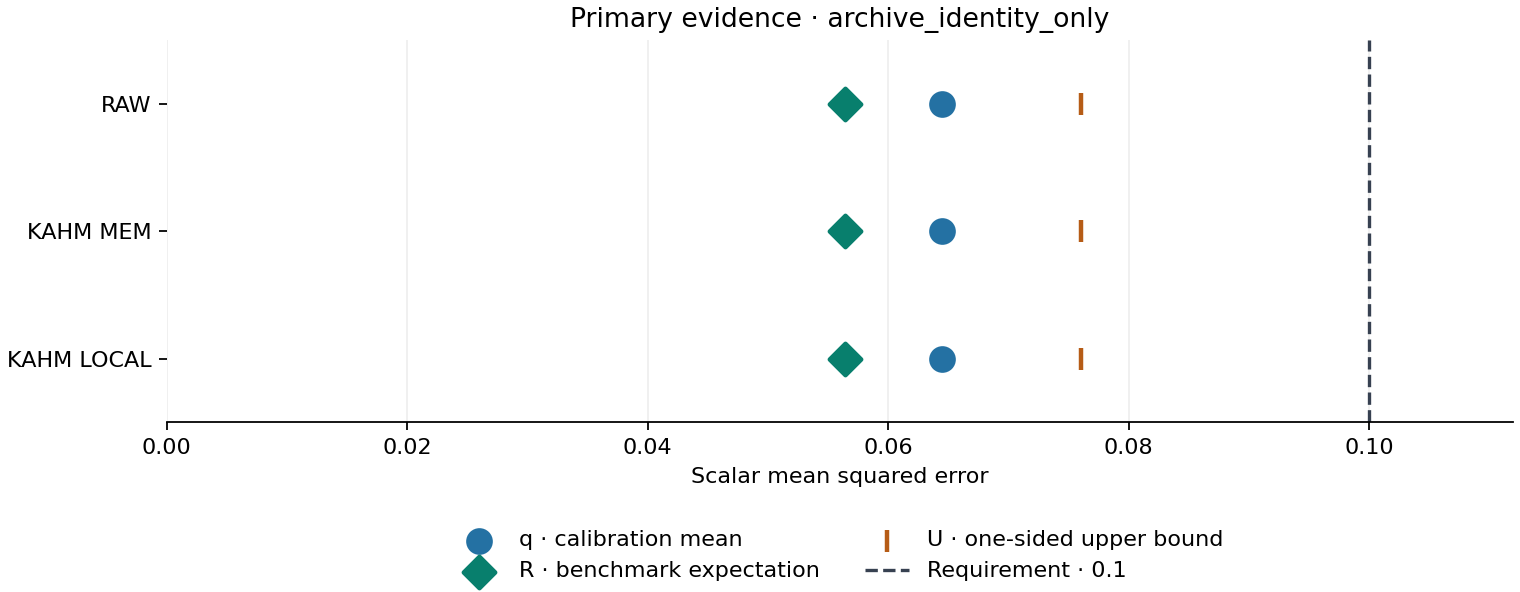

In [7]:
# Optional presentation only: this plots recorded numbers; it does not evaluate a model.
# The terminal inspection API works without NumPy or Matplotlib.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Optional figure skipped. Install the tutorial extra to render it; the table above is complete.")
else:
    from io import BytesIO
    rows = result["table"]
    labels = [row["candidate_id"].upper().replace("KAHM_", "KAHM ") for row in rows]
    fig, ax = plt.subplots(figsize=(9.5, 3.7), layout="constrained")
    for key, label, color, marker in (
        ("empirical_mse_decimal_18_approximate", "q · calibration mean", "#2471a3", "o"),
        ("population_mse_decimal_18_approximate", "R · benchmark expectation", "#087f6d", "D"),
        ("issued_upper_endpoint_decimal_18", "U · one-sided upper bound", "#b65c16", "|"),
    ):
        points = [(float(row[key]), i) for i, row in enumerate(rows) if row[key] is not None]
        if points:
            ax.scatter([point[0] for point in points], [point[1] for point in points],
                       label=label, color=color, marker=marker, s=100, linewidths=2, zorder=3)
    ax.axvline(0.1, color="#374151", linestyle="--", label="Requirement · 0.1")
    ax.set(yticks=range(len(rows)), yticklabels=labels, xlim=(0, 1.12 * max([0.1] + [float(row[key]) for row in rows for key in ("empirical_mse_decimal_18_approximate", "population_mse_decimal_18_approximate", "issued_upper_endpoint_decimal_18") if row[key] is not None])), ylim=(2.5, -0.5),
           xlabel="Scalar mean squared error", title="Primary evidence · " + result["mode"])
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2, frameon=False)
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=160)
    plt.close(fig)
    display(Image(data=buffer.getvalue(), alt="Three predictor rows comparing calibration q, population R, and issued U with the MSE requirement of 0.1. These are separate quantities, not two-sided intervals."))


## 6. Interpret the result without discarding difficult cases

| Certificate status | Meaning |
| --- | --- |
| `requirement_met` | The verified exact U satisfies U ≤ 1/10 under the stated premises |
| `unresolved` | A valid U exceeds 1/10; this does not establish that the actual risk exceeds 1/10 |
| `certificate_unavailable` | No endpoint was established under the fixed numerical procedure |

The separate audit reports `covered`, `coverage_miss`, or `endpoint_unavailable`.
All candidates and all outcomes are retained. A coverage miss is an observed
failure of a bound to cover this benchmark risk; it must not trigger selective
rerunning until a favorable result appears.

The table retains the actual status of every public primary candidate. This
is one realized audit. It does not estimate long-run coverage frequency or
demonstrate that a representation is generally superior. The benchmark's
Bayes risk is 9/160 = 0.05625; a realized sample mean q can lie below that
population reference without a contradiction.

To understand the mathematical and implementation layers, read
[the certificate design](../docs/CERTIFICATION_DESIGN.md) and
[the population audit](../docs/POPULATION_AUDIT.md).
[The fitted-risk guarantee](../docs/FITTED_RISK_GUARANTEE.md) supplies the
self-contained proof. The package assesses the particular implemented frozen
predictors under its stated evaluation assumptions.


## 7. Run one fresh experiment explicitly

Use a new directory. The command below performs the complete established
workflow in your runtime. It commits a reproduction plan before work, retains
all 225 development fits, freezes the selected three predictors, materializes
the reserved calibration stream, issues the assessment, and audits the result.

```bash
python -m kahm_demo reproduce --output runs/tutorial --master-seed 20261110 --run-id tutorial-v0.1
```

This command is displayed here; **the notebook does not execute it**. The output
contains `data/`, `encoders/`, `models/`, `frozen/`, `certificates/`, `audits/`, and
`reproduction.json`. Pipeline completion is distinct from certificate acceptance
or realized coverage. Partial failures and unfavorable results remain recorded;
there is no automatic resume, overwrite, resampling, or retry.

After a successful pipeline completion, verify that new run with:

```bash
python -m kahm_demo verify-audit --audit runs/tutorial/audits/audit.json --certificate runs/tutorial/certificates/certificate.json --bundle runs/tutorial/data --freeze runs/tutorial/frozen/freeze.json
```

The `tutorial` helper intentionally remains anchored to the original `primary`
evidence. It does not select a newly favorable run. Reusing a seed/run identity
is reproducibility, not new independent evidence. The public primary run ID
is `public-v0.1.0`.


## 8. Move toward a new application

This release is an executable controlled benchmark. It does not yet provide a
general CSV adapter or a theorem that makes arbitrary time-series windows iid.
The following decisions come before a new application-specific certificate:

| Decision | What must be made explicit |
| --- | --- |
| Forecast task | History, target, horizon, loss, and population distribution |
| Data separation | Training, validation, independent calibration, and leakage controls |
| Representation and decoder | KAHM construction, candidate menu, scaling, clipping, and fitting rules |
| Certificate premises | Loss range, calibration dependence assumptions, confidence allocation, and numerical method |
| Provenance | New source identities, runtime, model freeze, protocol, and retained outcomes |
| Optional oracle | Use an exact population audit only when the evaluation law permits it |

A justified fitted-risk upper bound need not have an exact population oracle.
For a general dataset, unknown R must remain unknown; it cannot be relabeled
from a test-set mean. Overlapping dependent windows need an appropriate sampling
or concentration argument, and changed targets or losses need newly justified
bounds. Multi-step latent rollouts require their own modeling and certification.

Continue with [the full tutorial](../docs/TUTORIAL.md) and
[the adaptation guide](../docs/ADAPTING_TO_NEW_DATA.md), which map these decisions
to the current modules. Validation evidence for this release is in
[the release validation report](../reports/RELEASE_VALIDATION.md).
